# 딥러닝및실습 숙제 #2 (Kaggle Titanic)

고도형 / 2021136004

`_08_learning_and_optimization/c_my_model_training_with_argparse_wandb.py`를 타이타닉 데이터에 맞게 고쳐서 생존 여부(0/1)를 맞히는 분류 모델을 만들었다.
순서는 요구사항 1(기본 훈련 + wandb) → 요구사항 2(활성화 함수, 배치 크기, 학습률 비교) → 요구사항 3(Early Stopping + submission.csv) → 요구사항 4(Kaggle 제출 결과)이다.

## 0. 준비

In [18]:
import os
import sys
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
import wandb

# titanic_dataset.py 안의 fillna(inplace=True)가 pandas FutureWarning을 계속 출력해서 출력이 지저분해짐 → 경고만 숨김
warnings.filterwarnings("ignore", category=FutureWarning)

# 이 노트북은 link_dl/_03_homeworks/homework_2/ 에 있음
CURRENT_PATH = os.getcwd()
BASE_PATH = os.path.abspath(os.path.join(CURRENT_PATH, os.path.pardir, os.path.pardir))
sys.path.append(BASE_PATH)        # _01_code._99_common_utils 를 import 하기 위해
sys.path.append(CURRENT_PATH)     # 같은 폴더의 titanic_dataset.py 를 import 하기 위해

from titanic_dataset import get_preprocessed_dataset
from _01_code._99_common_utils.early_stopping import EarlyStopping

USE_WANDB = True                   # wandb에 기록할지 여부 (False면 기록 안 함)
WANDB_PROJECT = "titanic_hw2"      # wandb 프로젝트 이름
SEED = 42

print("BASE_PATH:", BASE_PATH)
print("torch:", torch.__version__, "/ pandas:", pd.__version__, "/ wandb:", wandb.__version__)

BASE_PATH: C:\Users\godol\git_workspace\link_dl
torch: 2.14.0+cpu / pandas: 2.3.3 / wandb: 0.29.0


## 1. 데이터 준비

`titanic_dataset.py`의 `get_preprocessed_dataset()`을 그대로 사용한다. train.csv와 test.csv를 합쳐서 결측치를 채우고(Fare, Age, Embarked), 이름에서 호칭(title)을 뽑고, 가족 수(family_num)와 혼자 탔는지(alone) 열을 만든 뒤, 문자열 열을 숫자로 바꾼다.
결과는 특성 10개짜리 텐서이고, train 891명을 8:2로 나눠서 train 713명 / validation 178명, test 418명이 된다.

In [19]:
# random_split이 매번 다르게 나뉘면 실험끼리 비교가 안 되니까 시드를 먼저 고정
torch.manual_seed(SEED)
train_dataset, validation_dataset, test_dataset = get_preprocessed_dataset()

print("train: {0}, validation: {1}, test: {2}".format(
    len(train_dataset), len(validation_dataset), len(test_dataset)
))

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'title', 'family_num', 'alone'],
      dtype='object')
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked  title  \
0       0.0       3    1  22.0      1      0   7.2500         2      2   
1       1.0       1    0  38.0      1      0  71.2833         0      3   
2       1.0       3    0  26.0      0      0   7.9250         2      1   
3       1.0       1    0  35.0      1      0  53.1000         2      3   
4       0.0       3    1  35.0      0      0   8.0500         2      2   
5       0.0       3    1  29.0      0      0   8.4583         1      2   
6       0.0       1    1  54.0      0      0  51.8625         2      2   
7       0.0       3    1   2.0      3      1  21.0750         2      0   
8       1.0       3    0  27.0      0      2  11.1333         2      3   
9       1.0       2    0  14.0      1      0  30.0708         0      3   

   family_num  alone  
0           1    0.

Age(0-80), Fare(0-512)처럼 값 범위가 큰 열과 0/1짜리 열이 섞여 있어서 그대로 넣으면 학습이 불안정하다. 그래서 **train 데이터의 평균/표준편차로** 모든 열을 표준화했다. validation과 test도 train 통계로 바꾼다(검증·테스트 데이터 정보가 학습에 섞이지 않게).

In [20]:
# (추가) 표준화: train 부분의 평균/표준편차만 사용
full_X = train_dataset.dataset.X                  # random_split 결과는 Subset → .dataset 이 원래 TitanicDataset
train_X = full_X[train_dataset.indices]
X_mean = train_X.mean(dim=0)
X_std = train_X.std(dim=0)
X_std[X_std == 0] = 1.0                           # 혹시 표준편차가 0인 열이 있으면 나눗셈 방지

train_dataset.dataset.X = (full_X - X_mean) / X_std          # train/validation이 같은 원본을 공유하므로 한 번에 변환됨
test_dataset.X = (test_dataset.X - X_mean) / X_std

print("표준화 후 train 평균 (≈0):", train_dataset.dataset.X[train_dataset.indices].mean(dim=0).round(decimals=3))
print("표준화 후 train 표준편차 (≈1):", train_dataset.dataset.X[train_dataset.indices].std(dim=0).round(decimals=3))

표준화 후 train 평균 (≈0): tensor([0., -0., -0., -0., 0., -0., -0., 0., -0., -0.])
표준화 후 train 표준편차 (≈1): tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In [21]:
# 배치 모양 확인 (titanic_dataset.py 의 __main__ 부분과 같은 내용)
train_data_loader = DataLoader(dataset=train_dataset, batch_size=16, shuffle=True)
validation_data_loader = DataLoader(dataset=validation_dataset, batch_size=len(validation_dataset))
test_data_loader = DataLoader(dataset=test_dataset, batch_size=len(test_dataset))

for name, loader in [("TRAIN", train_data_loader), ("VALIDATION", validation_data_loader), ("TEST", test_data_loader)]:
    batch = next(iter(loader))
    target_shape = batch["target"].shape if "target" in batch else "-"
    print(f"[{name}] 배치 수: {len(loader)}, 첫 배치 input: {batch['input'].shape}, target: {target_shape}")

[TRAIN] 배치 수: 45, 첫 배치 input: torch.Size([16, 10]), target: torch.Size([16])
[VALIDATION] 배치 수: 1, 첫 배치 input: torch.Size([178, 10]), target: torch.Size([178])
[TEST] 배치 수: 1, 첫 배치 input: torch.Size([418, 10]), target: -


## 2. 모델, 학습 함수

c 예제의 `MyModel`을 기반으로 바꾼 점:
- 입력 8개 → **10개**, 출력 1개 → **2개**(사망/생존 두 클래스의 점수)
- 손실 함수 `MSELoss` → **`CrossEntropyLoss`** (분류 문제라서. 정답은 0/1 정수 라벨 그대로 넣으면 됨)
- 활성화 함수를 config로 바꿀 수 있게 함 (요구사항 2)
- 옵티마이저 `SGD` → **`Adam`**: SGD로 lr=1e-4를 주면 수백 epoch 동안 loss가 거의 안 줄어서 비교가 어려워서 Adam을 사용
- 배치가 `(input, target)` 튜플이 아니라 `{'input':..., 'target':...}` 딕셔너리라서 꺼내는 방식 수정
- loss 말고 **validation 정확도**도 같이 기록 (Kaggle 점수가 정확도라서)

In [22]:
ACTIVATIONS = {
    "Sigmoid": nn.Sigmoid,
    "ReLU": nn.ReLU,
    "ELU": nn.ELU,
    "LeakyReLU": nn.LeakyReLU,
}


class MyModel(nn.Module):
  def __init__(self, n_input, n_output, config):
    super().__init__()
    act = ACTIVATIONS[config["activation"]]          # 문자열로 받은 활성화 함수 클래스를 꺼냄
    h1, h2 = config["n_hidden_unit_list"]

    self.model = nn.Sequential(
      nn.Linear(n_input, h1),
      act(),
      nn.Linear(h1, h2),
      act(),
      nn.Linear(h2, n_output),                       # 마지막은 활성화 없이 점수(logit) 그대로 → CrossEntropyLoss가 softmax 포함
    )

  def forward(self, x):
    return self.model(x)


def get_model_and_optimizer(config):
  model = MyModel(n_input=10, n_output=2, config=config)
  optimizer = optim.Adam(model.parameters(), lr=config["learning_rate"])
  return model, optimizer


def evaluate(model, data_loader, loss_fn):
  # validation 데이터에 대한 평균 loss와 정확도
  model.eval()
  loss_sum, correct, n = 0.0, 0, 0
  with torch.no_grad():
    for batch in data_loader:
      output = model(batch["input"])
      loss_sum += loss_fn(output, batch["target"]).item() * len(batch["target"])
      correct += (output.argmax(dim=1) == batch["target"]).sum().item()   # 점수가 큰 쪽을 예측값으로
      n += len(batch["target"])
  model.train()
  return loss_sum / n, correct / n

In [23]:
def training_loop(model, optimizer, train_data_loader, validation_data_loader, config, run=None,
                  early_stopping=None, print_every=100):
  loss_fn = nn.CrossEntropyLoss()
  history = []

  for epoch in range(1, config["epochs"] + 1):
    loss_train, num_trains = 0.0, 0
    for train_batch in train_data_loader:
      output_train = model(train_batch["input"])
      loss = loss_fn(output_train, train_batch["target"])
      loss_train += loss.item()
      num_trains += 1

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    train_loss = loss_train / num_trains
    validation_loss, validation_acc = evaluate(model, validation_data_loader, loss_fn)
    history.append((epoch, train_loss, validation_loss, validation_acc))

    if run is not None:
      run.log({
        "Epoch": epoch,
        "Training loss": train_loss,
        "Validation loss": validation_loss,
        "Validation accuracy": validation_acc,
      })

    message = ""
    if early_stopping is not None:
      message, stop = early_stopping.check_and_save(validation_loss, model)
    else:
      stop = False

    if epoch % print_every == 0 or epoch == 1 or stop:
      print(f"Epoch {epoch:4d}, Training loss {train_loss:.4f}, "
            f"Validation loss {validation_loss:.4f}, Validation acc {validation_acc:.4f}  {message}")

    if stop:
      break

  return pd.DataFrame(history, columns=["epoch", "train_loss", "val_loss", "val_acc"])

In [24]:
def run_experiment(config, run_name, tags, early_stopping=None, print_every=100):
  # 실험마다 같은 조건에서 시작하도록 시드 고정 (가중치 초기값, 셔플 순서)
  torch.manual_seed(SEED)

  train_loader = DataLoader(dataset=train_dataset, batch_size=config["batch_size"], shuffle=True)
  validation_loader = DataLoader(dataset=validation_dataset, batch_size=len(validation_dataset))
  model, optimizer = get_model_and_optimizer(config)

  with wandb.init(
    mode="online" if USE_WANDB else "disabled",
    project=WANDB_PROJECT,
    name=run_name,
    tags=tags,
    config=config,
  ) as run:
    # x축을 Epoch로 사용하도록 지정
    run.define_metric("Training loss", step_metric="Epoch")
    run.define_metric("Validation loss", step_metric="Epoch", summary="min")
    run.define_metric("Validation accuracy", step_metric="Epoch", summary="max")

    history = training_loop(model, optimizer, train_loader, validation_loader, config,
                            run=run, early_stopping=early_stopping, print_every=print_every)

  best = history.loc[history["val_loss"].idxmin()]
  result = {
    "run": run_name,
    "min_val_loss": round(float(best["val_loss"]), 4),
    "best_epoch": int(best["epoch"]),
    "val_acc@best": round(float(best["val_acc"]), 4),
    "max_val_acc": round(float(history["val_acc"].max()), 4),
    "final_train_loss": round(float(history["train_loss"].iloc[-1]), 4),
    "final_val_loss": round(float(history["val_loss"].iloc[-1]), 4),
  }
  return model, history, result

## 3. [요구사항 1] 기본 훈련 + wandb 기록

기본 설정: 은닉층 [20, 20], ReLU, batch size 32, learning rate 1e-3, 500 epoch.
학습하면서 매 epoch마다 `run.log`로 Training loss / Validation loss를 wandb에 올린다.

In [25]:
BASE_CONFIG = {
  "epochs": 500,
  "batch_size": 32,
  "learning_rate": 1e-3,
  "n_hidden_unit_list": [20, 20],
  "activation": "ReLU",
}

base_model, base_history, base_result = run_experiment(
  BASE_CONFIG, run_name="1_base_relu_b32_lr1e-3", tags=["base"]
)
print(base_result)

Epoch    1, Training loss 0.6752, Validation loss 0.6447, Validation acc 0.7303  
Epoch  100, Training loss 0.3531, Validation loss 0.3897, Validation acc 0.8596  
Epoch  200, Training loss 0.3167, Validation loss 0.4132, Validation acc 0.8427  
Epoch  300, Training loss 0.2965, Validation loss 0.4413, Validation acc 0.8371  
Epoch  400, Training loss 0.2673, Validation loss 0.4684, Validation acc 0.8315  
Epoch  500, Training loss 0.2676, Validation loss 0.5235, Validation acc 0.8202  


Epoch,▁▁▁▂▂▂▂▂▂▂▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
Training loss,██▇▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Validation accuracy,▁█▇▇▇▇▇▇▇▇▇▇▇▆▆▆▇▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▅
Validation loss,▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇███
Epoch,500
Training loss,0.26762


{'run': '1_base_relu_b32_lr1e-3', 'min_val_loss': 0.3725, 'best_epoch': 18, 'val_acc@best': 0.8764, 'max_val_acc': 0.8876, 'final_train_loss': 0.2676, 'final_val_loss': 0.5235}


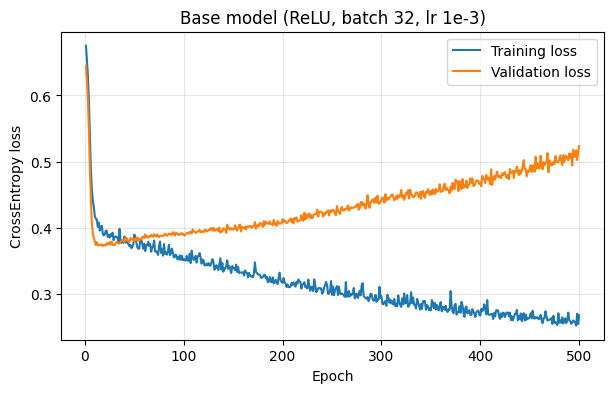

In [26]:
# (추가) wandb와 같은 그래프를 노트북에서도 확인
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(base_history["epoch"], base_history["train_loss"], label="Training loss")
plt.plot(base_history["epoch"], base_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy loss")
plt.title("Base model (ReLU, batch 32, lr 1e-3)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

고찰

Training loss는 끝까지 계속 내려갔는데, Validation loss는 18 epoch쯤 0.37로 가장 낮았다가 다시 올라가서 500 epoch에는 0.52까지 갔다. 정확도도 0.88에서 0.82로 떨어졌다. 데이터가 713개밖에 없어서 금방 과적합이 생긴 것 같다. 그래서 마지막 epoch 모델을 그대로 쓰면 안 될 것 같다.

c 예제를 분류용으로 바꾸면서 출력을 2개로, loss를 CrossEntropyLoss로 바꿨다. 정답을 one-hot으로 안 바꾸고 0, 1 그대로 넣으면 돼서 편했다.

## 4. [요구사항 2] 하이퍼파라미터 비교

비교 기준은 **validation loss의 최솟값**으로 정했다(같으면 그때의 정확도를 같이 봄). 한 번에 하나만 바꾸고 나머지는 고정했다.
1. 활성화 함수 4개 비교 (batch 32, lr 1e-3)
2. 1에서 가장 좋은 활성화 함수로 batch size 3개 비교 (lr 1e-3)
3. 1, 2에서 고른 값으로 learning rate 3개 비교

### 4-1. Activation Function: Sigmoid vs ReLU vs ELU vs Leaky ReLU

In [27]:
act_results = []
for act in ["Sigmoid", "ReLU", "ELU", "LeakyReLU"]:
  config = {**BASE_CONFIG, "activation": act}
  print("=" * 20, act, "=" * 20)
  _, _, result = run_experiment(config, run_name=f"2-1_act_{act}", tags=["activation"], print_every=250)
  result["activation"] = act
  act_results.append(result)

act_df = pd.DataFrame(act_results).set_index("activation").drop(columns="run")
best_activation = act_df["min_val_loss"].idxmin()
display(act_df)
print("가장 좋은 활성화 함수:", best_activation)

==================== Sigmoid ====================


Epoch    1, Training loss 0.6757, Validation loss 0.6287, Validation acc 0.7079  
Epoch  250, Training loss 0.4021, Validation loss 0.3742, Validation acc 0.8596  
Epoch  500, Training loss 0.3937, Validation loss 0.3824, Validation acc 0.8596  


Epoch,▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇███
Training loss,█▇▄▃▃▃▃▃▃▃▃▃▃▂▃▂▂▂▂▂▂▁▂▃▁▂▂▂▁▁▁▂▁▁▁▁▁▁▁▁
Validation accuracy,▁▄▄▄▄▅█████▇▆▆▇▆▆▅▅▇▇▆█▅▆▅▇▅▅▅▅▄▅▄▄▄▄▄▄▃
Validation loss,██▇▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Epoch,500
Training loss,0.39367


==================== ReLU ====================


Epoch    1, Training loss 0.6752, Validation loss 0.6447, Validation acc 0.7303  
Epoch  250, Training loss 0.2987, Validation loss 0.4267, Validation acc 0.8315  
Epoch  500, Training loss 0.2676, Validation loss 0.5235, Validation acc 0.8202  


...

==================== LeakyReLU ====================


Epoch    1, Training loss 0.6752, Validation loss 0.6447, Validation acc 0.7303  
Epoch  250, Training loss 0.2901, Validation loss 0.4275, Validation acc 0.8427  
Epoch  500, Training loss 0.2662, Validation loss 0.5401, Validation acc 0.8146  


Epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇█
Training loss,███▇▇▇▆▆▆▆▆▆▆▆▅▅▅▆▅▄▄▄▃▄▃▃▃▂▂▂▂▂▂▂▂▁▂▁▁▁
Validation accuracy,▁▃█▇▇▇▆▇▆▆▆▆▆▇▆▅▆▆▇▆▆▆▅▅▅▅▅▆▆▅▅▅▅▅▅▅▅▅▅▅
Validation loss,█▄▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▃▄▄▄▄▅▅▅▅
Epoch,500
Training loss,0.26619


,min_val_loss,best_epoch,val_acc@best,max_val_acc,final_train_loss,final_val_loss
activation,,,,,,
Sigmoid,0.3682,272,0.8708,0.8820,0.3937,0.3824
ReLU,0.3725,18,0.8764,0.8876,0.2676,0.5235
ELU,0.3649,50,0.8708,0.8876,0.3448,0.3975
LeakyReLU,0.3713,11,0.8708,0.8933,0.2662,0.5401


가장 좋은 활성화 함수: ELU


### 4-2. Batch Size: 32 vs 64 vs 128

In [28]:
bs_results = []
for bs in [32, 64, 128]:
  config = {**BASE_CONFIG, "activation": best_activation, "batch_size": bs}
  print("=" * 20, f"batch {bs}", "=" * 20)
  _, _, result = run_experiment(config, run_name=f"2-2_bs_{bs}", tags=["batch_size"], print_every=250)
  result["batch_size"] = bs
  bs_results.append(result)

bs_df = pd.DataFrame(bs_results).set_index("batch_size").drop(columns="run")
best_batch_size = int(bs_df["min_val_loss"].idxmin())
display(bs_df)
print("가장 좋은 batch size:", best_batch_size)

==================== batch 32 ====================


Epoch    1, Training loss 0.6777, Validation loss 0.6275, Validation acc 0.7472  
Epoch  250, Training loss 0.3523, Validation loss 0.3811, Validation acc 0.8708  
Epoch  500, Training loss 0.3448, Validation loss 0.3975, Validation acc 0.8427  


Epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇█
Training loss,█▅▅▅▄▄▄▄▄▃▄▄▃▄▄▃▃▄▃▃▃▂▂▂▂▂▂▂▁▂▁▂▂▁▁▁▁▁▁▁
Validation accuracy,▁▆██▇▆█▇▇▇▆▆▆▇▇▇█▇▇▇▆▇▇▆▆▆▆▆▆▆▇▆▆▆▆▆▆▆▆▆
Validation loss,▂▂▁▂▂▂▂▂▃▂▃▃▃▃▃▄▄▄▄▃▅▂▄▄▅▅▅▆▅▄▅▆▅▆▇▆▇█▇▇
Epoch,500
Training loss,0.3448


==================== batch 64 ====================


Epoch    1, Training loss 0.6922, Validation loss 0.6553, Validation acc 0.7191  
Epoch  250, Training loss 0.3576, Validation loss 0.3782, Validation acc 0.8764  
Epoch  500, Training loss 0.3660, Validation loss 0.3944, Validation acc 0.8596  


...

==================== batch 128 ====================


Epoch    1, Training loss 0.7039, Validation loss 0.6747, Validation acc 0.6404  
Epoch  250, Training loss 0.3777, Validation loss 0.3795, Validation acc 0.8652  
Epoch  500, Training loss 0.3533, Validation loss 0.3894, Validation acc 0.8483  


Epoch,▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇█
Training loss,█▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁
Validation accuracy,▁▁▆▇▇██▇▇▇█▇▇▇███▇██▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▆▇▆
Validation loss,█▇▂▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂
Epoch,500
Training loss,0.3533


,min_val_loss,best_epoch,val_acc@best,max_val_acc,final_train_loss,final_val_loss
batch_size,,,,,,
32,0.3649,50,0.8708,0.8876,0.3448,0.3975
64,0.3643,50,0.8652,0.8876,0.3660,0.3944
128,0.3672,77,0.8652,0.8876,0.3533,0.3894


가장 좋은 batch size: 64


### 4-3. Learning Rate: 1e-2 vs 1e-3 vs 1e-4

In [29]:
lr_results = []
for lr in [1e-2, 1e-3, 1e-4]:
  config = {**BASE_CONFIG, "activation": best_activation, "batch_size": best_batch_size, "learning_rate": lr}
  print("=" * 20, f"lr {lr}", "=" * 20)
  _, _, result = run_experiment(config, run_name=f"2-3_lr_{lr}", tags=["learning_rate"], print_every=250)
  result["learning_rate"] = lr
  lr_results.append(result)

lr_df = pd.DataFrame(lr_results).set_index("learning_rate").drop(columns="run")
best_learning_rate = float(lr_df["min_val_loss"].idxmin())
display(lr_df)
print("가장 좋은 learning rate:", best_learning_rate)

==================== lr 0.01 ====================


Epoch    1, Training loss 0.5681, Validation loss 0.4229, Validation acc 0.8146  
Epoch  250, Training loss 0.2746, Validation loss 0.5012, Validation acc 0.8258  
Epoch  500, Training loss 0.2504, Validation loss 0.7603, Validation acc 0.8146  


Epoch,▁▁▁▁▁▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
Training loss,▇█▇▇▇▇▆▇▆▆▅▅▅▅▅▅▆▄▄▄▃▄▄▄▂▃▂▄▂▃▂▂▂▁▂▁▂▂▃▁
Validation accuracy,▄▅▇█▇▅▅▃▆▄▃▃▄▅▃▄▄▅▃▄▃▃▄▃▄▂▃▁▁▃▄▃▂▂▃▂▂▃▃▃
Validation loss,▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▄▃▃▃▄▄▄▅▄▄▄▄▅▆▆▇▆▇███▇
Epoch,500
Training loss,0.25038


==================== lr 0.001 ====================


Epoch    1, Training loss 0.6922, Validation loss 0.6553, Validation acc 0.7191  
Epoch  250, Training loss 0.3576, Validation loss 0.3782, Validation acc 0.8764  
Epoch  500, Training loss 0.3660, Validation loss 0.3944, Validation acc 0.8596  


...

==================== lr 0.0001 ====================


Epoch    1, Training loss 0.7114, Validation loss 0.6954, Validation acc 0.3989  
Epoch  250, Training loss 0.4082, Validation loss 0.3717, Validation acc 0.8708  
Epoch  500, Training loss 0.4254, Validation loss 0.3677, Validation acc 0.8708  


Epoch,▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇████
Training loss,█▇▆▆▅▄▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▁▁▂▂▂▁▁▂▁▂▁▁▁▁▂▁▁
Validation accuracy,▁▆▆▆▇▇▇▇██▇▇▇▇▇▇▇███████████████████████
Validation loss,█▇▇▆▆▄▄▃▃▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
Epoch,500
Training loss,0.42542


,min_val_loss,best_epoch,val_acc@best,max_val_acc,final_train_loss,final_val_loss
learning_rate,,,,,,
0.0100,0.3591,28,0.8764,0.8876,0.2504,0.7603
0.0010,0.3643,50,0.8652,0.8876,0.3660,0.3944
0.0001,0.3670,459,0.8708,0.8876,0.4254,0.3677


가장 좋은 learning rate: 0.01


In [30]:
print("최종 선택:", {"activation": best_activation, "batch_size": best_batch_size, "learning_rate": best_learning_rate})

최종 선택: {'activation': 'ELU', 'batch_size': 64, 'learning_rate': 0.01}


고찰

활성화 함수는 ELU가 validation loss 0.365로 가장 낮았다. ReLU랑 LeakyReLU는 10-20 epoch만에 최저점을 찍고 바로 과적합이 심해졌고, Sigmoid는 느리지만 끝까지 안정적이었다. ELU는 그 중간 정도였다.

batch size는 64가 가장 좋았지만 32와 거의 차이가 없었다. 128은 epoch당 업데이트 횟수가 적어서 처음에 학습이 느렸다.

learning rate는 1e-2가 28 epoch에 가장 낮은 loss가 나왔지만, 계속 돌리면 validation loss가 0.76까지 올라갔다. 1e-4는 너무 느려서 400 epoch 넘어서야 최저점이 나왔다.

전체적으로 차이가 0.01도 안 나서, validation 데이터가 178개뿐인 걸 생각하면 우연일 수도 있을 것 같다. 시드를 바꿔서 여러 번 돌려 보면 더 정확할 것 같다.

## 5. [요구사항 3] 최종 모델 훈련, Early Stopping, submission.csv

4에서 고른 하이퍼파라미터로 다시 훈련한다. epoch를 넉넉하게(1000) 주고, `_99_common_utils/early_stopping.py`의 `EarlyStopping`으로 validation loss가 30 epoch 동안 더 좋아지지 않으면 멈춘다.
EarlyStopping은 validation loss가 가장 낮아질 때마다 모델을 저장하므로, 멈춘 뒤 **그 저장된 모델(가장 좋았던 epoch)**을 불러와서 test 데이터를 예측한다.

In [31]:
FINAL_CONFIG = {
  **BASE_CONFIG,
  "epochs": 1000,
  "activation": best_activation,
  "batch_size": best_batch_size,
  "learning_rate": best_learning_rate,
  "early_stopping_patience": 30,
}

CHECKPOINT_PATH = os.path.join(CURRENT_PATH, "checkpoints")
os.makedirs(CHECKPOINT_PATH, exist_ok=True)
run_time_str = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S")

early_stopping = EarlyStopping(
  patience=FINAL_CONFIG["early_stopping_patience"],
  project_name="titanic",
  checkpoint_file_path=CHECKPOINT_PATH,
  run_time_str=run_time_str,
)

final_model, final_history, final_result = run_experiment(
  FINAL_CONFIG, run_name="3_final_early_stopping", tags=["final"],
  early_stopping=early_stopping, print_every=20,
)
print(final_result)

Epoch    1, Training loss 0.5681, Validation loss 0.4229, Validation acc 0.8146  Early stopping is stated!
Epoch   20, Training loss 0.3933, Validation loss 0.3770, Validation acc 0.8596  Early stopping counter: 10 out of 30
Epoch   40, Training loss 0.4060, Validation loss 0.3848, Validation acc 0.8539  Early stopping counter: 12 out of 30
Epoch   58, Training loss 0.3823, Validation loss 0.3793, Validation acc 0.8596  Early stopping counter: 30 out of 30 *** TRAIN EARLY STOPPED! ***


Epoch,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
Training loss,█▅▄▄▃▃▃▃▃▂▃▃▂▂▂▃▂▂▃▃▂▃▂▂▂▂▂▂▂▃▂▂▂▁▁▃▂▂▁▃
Validation accuracy,▁▄█▄▇▅▇▆▇▅▇▅▅▆▅▅▃▇▆▆▄▅▂▄▅▄▅▆▆▆▅▅▅▅▃▆▅▇▅▅
Validation loss,█▃▃▄▃▂▃▂▁▁▂▃▂▂▁▃▃▄▃▄▄▂▃▃▄▂▃▃▄▆▃▂▄▃▃▂▂▂▂▃
Epoch,58
Training loss,0.38229


{'run': '3_final_early_stopping', 'min_val_loss': 0.3591, 'best_epoch': 28, 'val_acc@best': 0.8764, 'max_val_acc': 0.8876, 'final_train_loss': 0.3823, 'final_val_loss': 0.3793}


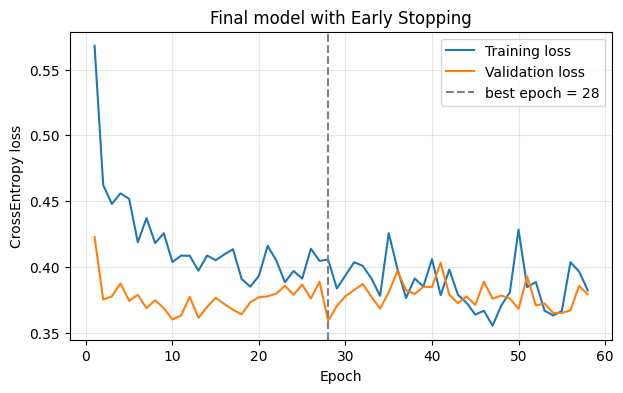

In [32]:
plt.figure(figsize=(7, 4))
plt.plot(final_history["epoch"], final_history["train_loss"], label="Training loss")
plt.plot(final_history["epoch"], final_history["val_loss"], label="Validation loss")
plt.axvline(final_result["best_epoch"], color="gray", linestyle="--", label=f"best epoch = {final_result['best_epoch']}")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy loss")
plt.title("Final model with Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [33]:
# 가장 validation loss가 낮았던 시점의 가중치 불러오기
best_model, _ = get_model_and_optimizer(FINAL_CONFIG)
best_model.load_state_dict(torch.load(early_stopping.latest_file_path))
best_model.eval()

loss_fn = nn.CrossEntropyLoss()
val_loader = DataLoader(dataset=validation_dataset, batch_size=len(validation_dataset))
val_loss, val_acc = evaluate(best_model, val_loader, loss_fn)
print(f"불러온 모델 → Validation loss {val_loss:.4f}, Validation acc {val_acc:.4f}")

불러온 모델 → Validation loss 0.3591, Validation acc 0.8764


In [34]:
# test 데이터 418명 예측 → submission.csv 생성
with torch.no_grad():
  test_batch = next(iter(test_data_loader))           # batch_size=418 이라 한 번에 전부
  test_pred = best_model(test_batch["input"]).argmax(dim=1)

test_df = pd.read_csv(os.path.join(CURRENT_PATH, "test.csv"))
submission = pd.DataFrame({
  "PassengerId": test_df["PassengerId"],
  "Survived": test_pred.numpy().astype(int),
})
submission_path = os.path.join(CURRENT_PATH, "submission.csv")
submission.to_csv(submission_path, index=False)

print(submission.shape)
print(submission.head(10))
print("예측 생존 비율:", round(submission["Survived"].mean(), 3))

(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0
5          897         0
6          898         1
7          899         0
8          900         1
9          901         0
예측 생존 비율: 0.364


고찰

앞에서 본 것처럼 오래 학습하면 validation loss가 다시 올라가니까, 마지막 epoch가 아니라 validation loss가 가장 낮았던 epoch의 모델로 테스트해야 한다고 생각했다.

그래서 EarlyStopping(patience=30)을 썼다. 28 epoch에서 validation loss가 0.359로 가장 낮았고, 그 뒤 30 epoch 동안 좋아지지 않아서 58 epoch에서 멈췄다. 멈춘 시점 모델이 아니라 28 epoch 때 저장된 모델을 불러와서 submission.csv를 만들었다. 예측한 생존 비율은 36% 정도로 train 데이터(약 38%)와 비슷했다.

## 6. [요구사항 4] Kaggle 제출 결과

Kaggle에 submission.csv를 제출한 결과 점수 0.77990, 리더보드 3731등이 나왔다.

<img width="1512" alt="leaderboard" src="https://github.com/user-attachments/assets/c34ceac3-4481-4370-8eb5-8450d4532ccb" />

### 숙제 후기

1차 숙제는 예제를 따라 하는 거였는데, 이번에는 직접 모델을 바꾸고 실험해야 해서 더 오래 걸린 것 같다. 그래도 wandb로 그래프가 바로 그려지니까 실험 결과를 비교하기는 편했다.

제일 기억에 남는 건 과적합이다. training loss는 계속 내려가는데 validation loss는 금방 다시 올라가는 걸 보고, 왜 Early Stopping이 필요한지 바로 이해가 됐다. learning rate를 크게 하면 빨리 좋아지지만 금방 망가지는 것도 그래프로 보니까 확실히 느껴졌다.
아쉬운 점은 validation에서는 87%가 나왔는데 Kaggle 점수는 78%였다는 거다. 데이터가 적어서 validation 점수만 믿으면 안 된다는 걸 알게 됐다.